# Smartphone ML Intelligence

## 05 — Smartphone Market Segmentation

### Objective

Segment currently available smartphones into four interpretable market groups using numerical characteristics related to price, performance, display, battery, charging, camera, and form factor.


The main objective is then to determine:

- how the four smartphone groups differ,
- which numerical features contribute most strongly to separating them,
- how brands and categorical technologies are distributed across the resulting segments,
- and whether the four-cluster representation produces meaningful market categories.

### 1. Importing and Loading 

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import duckdb

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


In [2]:
DATA_PATH = Path("../data/processed/phones_clean.csv")

data = pd.read_csv(
    DATA_PATH,
    parse_dates=["launch_date"]
)

con = duckdb.connect()
con.register("phones", data)

query = """
SELECT *
FROM phones
WHERE availability=1
"""

phones = con.execute(query).df()


print(f"Rows: {phones.shape[0]}")
print(f"Columns: {phones.shape[1]}")

phones.head()

Rows: 155
Columns: 48


,name,brand,sale,processor_type,processor,fab,ram_type,rom_type,display_type,size,...,speaker,wireless_charging,ip_rating,price,availability,has_ultrawide,has_third_camera,has_fourth_camera,launch_year,phone_age_days
0,Galaxy A07,Samsung,Offline,Mediatek,Dimensity 6300,6,LPDDR4X,UFS 2.2,IPS LCD,6.7,...,Mono,False,54,20000,1,False,True,False,2026,275
1,Galaxy A17,Samsung,Offline,Exynos,1330,5,LPDDR4X,UFS 2.2,Amoled,6.7,...,Mono,False,54,28000,1,True,True,False,2025,435
2,Galaxy A27,Samsung,Offline,Snapdragon,6 Gen 3,4,LPDDR5X,UFS 3.1,Amoled,6.7,...,Mono,False,64,36000,1,True,True,False,2026,135
3,Galaxy A36,Samsung,Offline,Snapdragon,6 Gen 3,4,LPDDR5,UFS 2.2,Amoled,6.7,...,Stereo,False,67,36500,1,True,True,False,2025,615
4,Galaxy A37,Samsung,Offline,Exynos,1480,4,LPDDR5X,UFS 3.1,Amoled,6.7,...,Stereo,False,68,47000,1,True,True,False,2026,227


### 2. Analysing Features

In [3]:
def encode_binary_features(df):
    df = df.copy()

    df["display_type"] = df["display_type"].map({
        "Amoled": 1,
        "IPS LCD": 0
    })

    df["curved_display"] = df["curved_display"].astype(int)

    df["wireless_charging"] = df["wireless_charging"].astype(int)

    return df

In [4]:
phones_encoded = encode_binary_features(phones)

In [5]:
continuous_features = [
    "price",
    "antutu",
    "refresh_rate",
    "battery",
    "charging_speed",
    "main",
    "useful_camera_number",
    "size",
    "ppi",
    "thickness",
    "ip_rating"
]

binary_features = [
    "display_type",
    "curved_display",
    "wireless_charging"
]

features = continuous_features + binary_features

X = phones_encoded[features].copy()

print("Number of smartphones:", X.shape[0])
print("Number of clustering features:", X.shape[1])

X.head()

Number of smartphones: 155
Number of clustering features: 14


,price,antutu,refresh_rate,battery,charging_speed,main,useful_camera_number,size,ppi,thickness,ip_rating,display_type,curved_display,wireless_charging
0,20000,450401,120,6000,25,50,1,6.7,262,8.2,54,0,0,0
1,28000,473905,90,5000,25,50,2,6.7,358,7.5,54,1,0,0
2,36000,892500,120,5000,25,50,2,6.7,385,7.8,64,1,0,0
3,36500,620000,120,5000,45,50,3,6.7,385,7.4,67,1,0,0
4,47000,713393,120,5000,45,50,2,6.7,385,7.4,68,1,0,0


### 3. Scaling 

In [6]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = pd.DataFrame(
    scaler.fit_transform(X),
    columns=features,
    index=X.index
)

X_scaled.head()

,price,antutu,refresh_rate,battery,charging_speed,main,useful_camera_number,size,ppi,thickness,ip_rating,display_type,curved_display,wireless_charging
0,-0.771018,-0.883839,-0.375523,-0.352398,-1.061666,-0.22237,-1.087939,-0.081803,-1.644261,0.121051,-2.418510,-1.58831,-0.373773,-0.510061
1,-0.568097,-0.861328,-2.277680,-1.096480,-1.061666,-0.22237,0.099600,-0.081803,-0.462357,-1.118009,-2.418510,0.62960,-0.373773,-0.510061
2,-0.365176,-0.460427,-0.375523,-1.096480,-1.061666,-0.22237,0.099600,-0.081803,-0.129946,-0.586983,-0.354253,0.62960,-0.373773,-0.510061
3,-0.352494,-0.721409,-0.375523,-1.096480,-0.348057,-0.22237,1.287139,-0.081803,-0.129946,-1.295018,0.265024,0.62960,-0.373773,-0.510061
4,-0.086160,-0.631963,-0.375523,-1.096480,-0.348057,-0.22237,0.099600,-0.081803,-0.129946,-1.295018,0.471450,0.62960,-0.373773,-0.510061


### 4. Running the four-cluster model

In [7]:
from sklearn.cluster import KMeans

N_CLUSTERS = 6
RANDOM_STATE = 42

kmeans = KMeans(
    n_clusters=N_CLUSTERS,
    random_state=RANDOM_STATE,
    n_init=20
)

cluster_labels = kmeans.fit_predict(X_scaled)

In [8]:
segmented_phones = phones.copy()

segmented_phones["cluster"] = cluster_labels

In [9]:
cluster_distribution = (
    segmented_phones["cluster"]
    .value_counts()
    .sort_index()
    .to_frame("smartphones")
)

cluster_distribution["share_pct"] = (
    cluster_distribution["smartphones"]
    / len(segmented_phones)
    * 100
).round(2)

cluster_distribution

,smartphones,share_pct
cluster,,
0,19,12.26
1,44,28.39
2,25,16.13
3,15,9.68
4,34,21.94
5,18,11.61


### 5. Numerical cluster profiles

In [10]:
cluster_numeric_profile = (
    segmented_phones
    .groupby("cluster")[continuous_features]
    .mean()
    .round(2)
)

cluster_numeric_profile

,price,antutu,refresh_rate,battery,charging_speed,main,useful_camera_number,size,ppi,thickness,ip_rating
cluster,,,,,,,,,,,
0,35368.42,1117311.95,136.26,6877.47,64.11,68.84,1.95,6.79,437.26,7.90,67.79
1,20261.36,579392.84,124.64,6668.18,31.43,41.09,1.11,6.78,285.98,8.47,62.70
2,96920.00,2213126.64,115.20,4965.80,47.48,55.36,2.64,6.43,456.88,7.86,68.16
3,120333.33,3617194.80,135.60,6636.73,87.67,109.87,3.07,6.81,476.33,8.26,68.80
4,41411.76,1246259.21,130.50,7701.18,80.24,63.24,1.74,6.74,436.18,8.19,68.29
5,34000.00,787356.61,116.33,5211.11,36.44,50.00,2.22,6.72,390.17,7.70,60.06


### 5. Binary Feature Profiles

In [11]:
binary_profile = phones_encoded[
    binary_features
].copy()

binary_profile["cluster"] = cluster_labels

cluster_binary_profile = (
    binary_profile
    .groupby("cluster")[binary_features]
    .mean()
    .mul(100)
    .round(1)
)

cluster_binary_profile

,display_type,curved_display,wireless_charging
cluster,,,
0,100.0,100.0,10.5
1,0.0,0.0,0.0
2,100.0,0.0,56.0
3,100.0,0.0,100.0
4,100.0,0.0,2.9
5,100.0,0.0,0.0


### 6. Combining Profiles Visually

In [12]:
scaled_profile = X_scaled.copy()
scaled_profile["cluster"] = cluster_labels

cluster_standardized_profile = (
    scaled_profile
    .groupby("cluster")
    .mean()
    .round(2)
)

cluster_standardized_profile

,price,antutu,refresh_rate,battery,charging_speed,main,useful_camera_number,size,ppi,thickness,ip_rating,display_type,curved_display,wireless_charging
cluster,,,,,,,,,,,,,,
0,-0.38,-0.25,0.66,0.30,0.33,0.23,0.04,0.43,0.51,-0.41,0.43,0.63,2.68,-0.25
1,-0.76,-0.76,-0.08,0.14,-0.83,-0.43,-0.95,0.41,-1.35,0.60,-0.62,-1.59,-0.37,-0.51
2,1.18,0.80,-0.68,-1.12,-0.26,-0.09,0.86,-1.64,0.76,-0.47,0.50,0.63,-0.37,0.87
3,1.77,2.15,0.61,0.12,1.17,1.20,1.37,0.54,0.99,0.22,0.64,0.63,-0.37,1.96
4,-0.23,-0.12,0.29,0.91,0.91,0.09,-0.21,0.17,0.50,0.11,0.53,0.63,-0.37,-0.44
5,-0.42,-0.56,-0.61,-0.94,-0.65,-0.22,0.36,0.04,-0.07,-0.76,-1.17,0.63,-0.37,-0.51


### 7. Heatmap of Cluster Characterstics

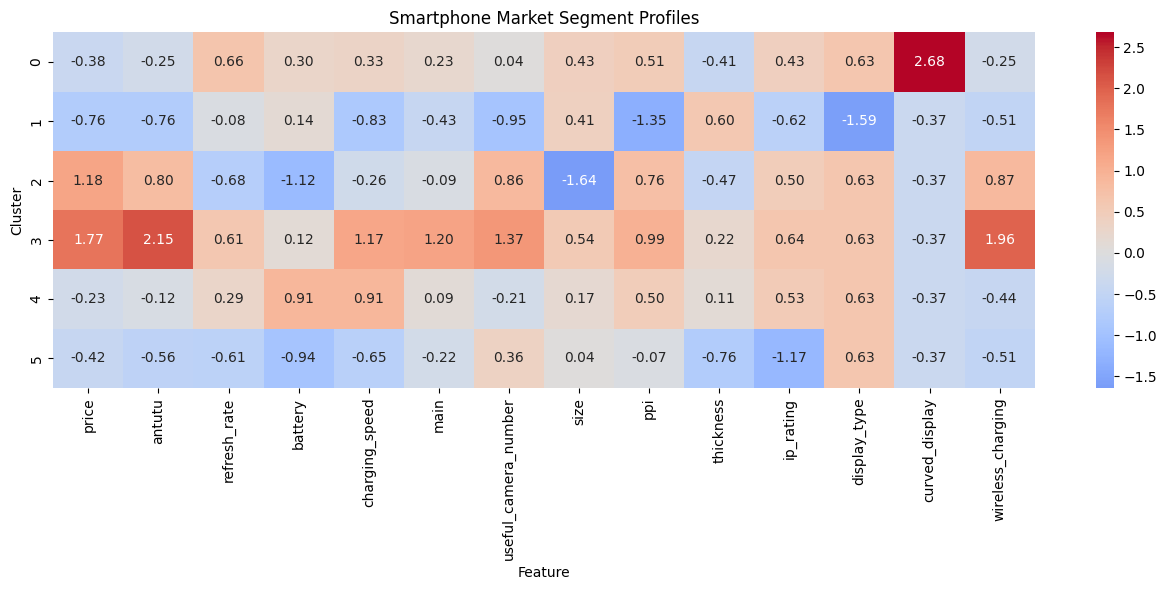

In [13]:
plt.figure(figsize=(13, 6))

sns.heatmap(
    cluster_standardized_profile,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Smartphone Market Segment Profiles")
plt.xlabel("Feature")
plt.ylabel("Cluster")

plt.tight_layout()
plt.show()

### 8. Finding Representative Smartphones

In [14]:
distances = kmeans.transform(X_scaled)

for cluster in range(N_CLUSTERS):

    cluster_mask = cluster_labels == cluster

    cluster_indices = X_scaled.index[
        cluster_mask
    ]

    cluster_distances = distances[
        cluster_mask,
        cluster
    ]

    representative_indices = (
        pd.Series(
            cluster_distances,
            index=cluster_indices
        )
        .sort_values()
        .head(10)
        .index
    )

    print(f"\nCluster {cluster}")

    display(
        segmented_phones.loc[
            representative_indices,
            [
                "brand",
                "name",
                "price",
                "size",
                "ppi",
                "antutu",
                "battery",
                "charging_speed",
                "main",
                "useful_camera_number",
                "refresh_rate",
                "thickness",
                "display_type",
                "curved_display",
                "wireless_charging"
            ]
        ]
    )


Cluster 0


,brand,name,price,size,ppi,antutu,battery,charging_speed,main,useful_camera_number,refresh_rate,thickness,display_type,curved_display,wireless_charging
47,Motorola,Moto Edge 70 Fusion,31000,6.78,450,1132967,7000,68,50,2,144,7.90,Amoled,True,False
105,Realme,Realme P4 Pro,29000,6.80,453,1072656,7000,80,50,2,144,7.70,Amoled,True,False
131,Vivo,Vivo T5,35000,6.83,450,1111603,7050,45,50,2,144,8.00,Amoled,True,False
39,IQOO,Iqoo Z11,35000,6.83,450,1111603,7050,45,50,2,144,8.00,Amoled,True,False
123,Tecno,Tecno Camon 50 Ultra,40000,6.78,429,944781,6500,45,50,3,144,7.75,Amoled,True,False
129,Vivo,Vivo S2,43000,6.89,450,960000,7050,44,50,1,120,8.00,Amoled,True,False
46,Motorola,Moto Edge 60 Fusion,23000,6.67,446,700000,5500,68,50,2,120,8.30,Amoled,True,False
49,Motorola,Moto Edge 70 Pro,39000,6.80,449,2173245,6500,90,50,2,144,7.20,Amoled,True,False
127,Tecno,Tecno Pova Curve 2,28000,6.78,429,768617,8000,45,50,1,144,7.40,Amoled,True,False
27,Infinix,Infinix Note Edge,27000,6.78,429,719969,6500,45,50,1,120,7.20,Amoled,True,False



Cluster 1


,brand,name,price,size,ppi,antutu,battery,charging_speed,main,useful_camera_number,refresh_rate,thickness,display_type,curved_display,wireless_charging
75,Oppo,Oppo K14x,16000,6.75,256,415000,6500,45,50,1,120,8.60,IPS LCD,False,False
151,Tecno,Tecno Spark 50s,20000,6.78,256,675000,6500,45,50,1,120,8.20,IPS LCD,False,False
128,Tecno,Tecno Spark 50,17000,6.78,256,521017,6500,45,50,1,120,8.20,IPS LCD,False,False
124,Tecno,Tecno Pop X,16000,6.78,256,521017,6500,45,13,1,120,8.20,IPS LCD,False,False
65,OnePlus,Oneplus N6x,21000,6.80,254,577520,7000,15,13,1,120,8.70,IPS LCD,False,False
150,Xiaomi,Redmi 17C,21000,6.90,254,630000,6000,33,50,1,120,8.10,IPS LCD,False,False
42,Lava,Lava Bold N2,13000,6.75,260,515768,6000,18,13,1,120,8.75,IPS LCD,False,False
149,Realme,Realme C100i,16000,6.81,254,308467,6500,15,8,1,120,8.70,IPS LCD,False,False
44,Lava,Lava Virat V1,13000,6.75,262,500000,6000,18,13,1,120,8.80,IPS LCD,False,False
111,Xiaomi,Redmi 15C,18500,6.90,254,467924,6000,33,50,1,120,8.00,IPS LCD,False,False



Cluster 2


,brand,name,price,size,ppi,antutu,battery,charging_speed,main,useful_camera_number,refresh_rate,thickness,display_type,curved_display,wireless_charging
29,Apple,iPhone 17,100000,6.30,460,2221350,3692,40,48,2,120,8.0,Amoled,False,True
83,Google,Pixel 11 Pro,120000,6.30,497,1933536,4850,30,50,3,120,8.4,Amoled,False,False
82,Google,Pixel 11,90000,6.30,422,1863536,4985,30,48,3,120,8.6,Amoled,False,False
20,Samsung,Galaxy S25+,100000,6.70,513,2528942,4900,45,50,3,120,7.3,Amoled,False,True
143,Xiaomi,Xiaomi 17T,70000,6.59,460,2137999,6500,67,50,3,120,8.2,Amoled,False,False
22,Samsung,Galaxy S26 FE,73000,6.70,385,2533050,4900,45,50,3,120,7.4,Amoled,False,True
79,Google,Pixel 10 Pro,110000,6.30,495,1067193,4870,30,50,3,120,8.5,Amoled,False,False
21,Samsung,Galaxy S26,103000,6.30,411,3504102,4300,25,50,3,120,7.2,Amoled,False,True
18,Samsung,Galaxy S25 FE,60000,6.70,385,2073050,4900,45,50,3,120,7.4,Amoled,False,True
138,Vivo,Vivo X300 FE,90000,6.31,460,2895309,6500,90,50,3,120,8.2,Amoled,False,True


... (2 outputs left out)


Cluster 4


,brand,name,price,size,ppi,antutu,battery,charging_speed,main,useful_camera_number,refresh_rate,thickness,display_type,curved_display,wireless_charging
107,Realme,Realme P4s,35000,6.78,454,991423,8000,80,50,2,144,8.6,Amoled,False,False
148,Oppo,Oppo F35 Pro,45000,6.78,450,938845,8000,80,50,1,144,8.4,Amoled,False,False
67,OnePlus,Oneplus Nord CE 6,38000,6.78,450,1148866,8000,80,50,1,144,8.5,Amoled,False,False
37,IQOO,Iqoo Neo 10R,27000,6.78,452,1540721,6400,80,50,2,144,8.0,Amoled,False,False
122,Xiaomi,Redmi Turbo 5,42000,6.59,460,2133558,7540,100,50,2,120,8.2,Amoled,False,False
70,Oppo,Oppo F33 Pro,38000,6.59,397,651333,7000,80,50,1,120,8.3,Amoled,False,False
132,Vivo,Vivo T5 Pro,42000,6.83,450,1167329,9020,90,50,1,144,8.3,Amoled,False,False
69,Oppo,Oppo F33,32000,6.59,397,651333,7000,80,50,1,120,8.0,Amoled,False,False
103,Realme,Realme P4,26000,6.77,388,777255,7000,80,50,2,144,7.6,Amoled,False,False
99,Realme,Realme GT 7T,35000,6.80,453,1761804,7000,120,50,2,120,8.3,Amoled,False,False



Cluster 5


,brand,name,price,size,ppi,antutu,battery,charging_speed,main,useful_camera_number,refresh_rate,thickness,display_type,curved_display,wireless_charging
2,Samsung,Galaxy A27,36000,6.70,385,892500,5000,25,50,2,120,7.8,Amoled,False,False
15,Samsung,Galaxy M47,38000,6.70,385,892500,6000,45,50,2,120,7.8,Amoled,False,False
10,Samsung,Galaxy F70 Pro,38000,6.70,385,892500,6000,45,50,2,120,7.8,Amoled,False,False
152,Samsung,Galaxy F70,20000,6.70,385,473905,5000,25,50,2,120,7.5,Amoled,False,False
56,Nothing,Nothing Phone 3a Lite,28000,6.77,392,675102,5000,33,50,2,120,8.3,Amoled,False,False
8,Samsung,Galaxy F36,21000,6.70,385,595209,5000,25,50,2,120,7.7,Amoled,False,False
14,Samsung,Galaxy M36,21000,6.70,385,595209,5000,25,50,2,120,7.7,Amoled,False,False
4,Samsung,Galaxy A37,47000,6.70,385,713393,5000,45,50,2,120,7.4,Amoled,False,False
3,Samsung,Galaxy A36,36500,6.70,385,620000,5000,45,50,3,120,7.4,Amoled,False,False
5,Samsung,Galaxy A56,45000,6.70,385,908689,5000,45,50,3,120,7.4,Amoled,False,False


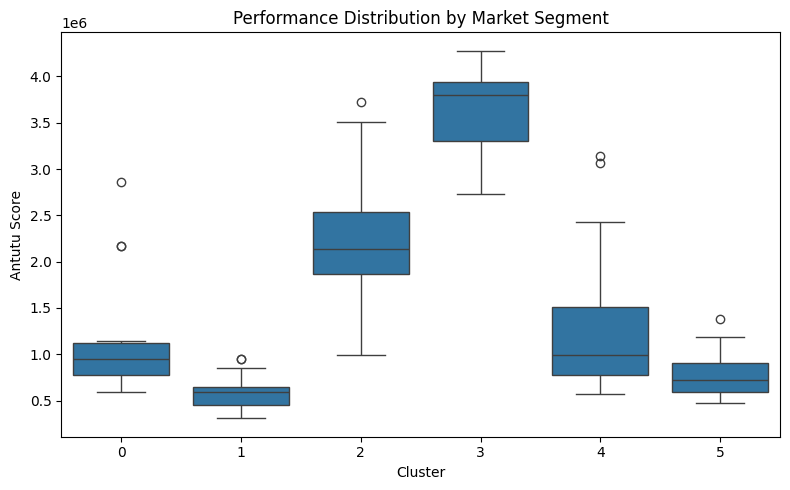

In [15]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=segmented_phones,
    x="cluster",
    y="antutu"
)

plt.title("Performance Distribution by Market Segment")
plt.xlabel("Cluster")
plt.ylabel("Antutu Score")

plt.tight_layout()
plt.show()

### 9. Processor Type by Cluster

In [16]:
processor_cluster = pd.crosstab(
    segmented_phones["processor_type"],
    segmented_phones["cluster"],
    normalize="index"
).round(2)

processor_cluster

cluster,0,1,2,3,4,5
processor_type,,,,,,
Apple Bionic,0.00,0.00,0.83,0.17,0.00,0.00
Exynos,0.00,0.00,0.29,0.00,0.00,0.71
Mediatek,0.18,0.44,0.03,0.06,0.27,0.02
Snapdragon,0.14,0.08,0.14,0.20,0.31,0.14
Tensor,0.00,0.00,1.00,0.00,0.00,0.00
Unisoc,0.00,1.00,0.00,0.00,0.00,0.00


### 10. Display Type by Cluster

In [17]:
display_cluster = pd.crosstab(
    segmented_phones["display_type"],
    segmented_phones["cluster"],
    normalize="index"
).round(2)

display_cluster

cluster,0,1,2,3,4,5
display_type,,,,,,
Amoled,0.17,0.0,0.23,0.14,0.31,0.16
IPS LCD,0.00,1.0,0.00,0.00,0.00,0.00


### 11. RAM and Storage Type by Cluster

In [18]:
pd.crosstab(
    segmented_phones["ram_type"],
    segmented_phones["cluster"],
    normalize="index"
).round(2)

cluster,0,1,2,3,4,5
ram_type,,,,,,
LPDDR4X,0.14,0.51,0.00,0.00,0.24,0.11
LPDDR5,0.14,0.00,0.29,0.00,0.29,0.29
LPDDR5X,0.10,0.04,0.34,0.22,0.19,0.10


In [19]:
pd.crosstab(
    segmented_phones["rom_type"],
    segmented_phones["cluster"],
    normalize="index"
).round(2)

cluster,0,1,2,3,4,5
rom_type,,,,,,
NVMe,0.00,0.00,0.83,0.17,0.00,0.00
UFS 2.2,0.12,0.58,0.00,0.00,0.16,0.13
UFS 3.1,0.22,0.14,0.08,0.00,0.31,0.25
UFS 4.0,0.00,0.00,0.76,0.12,0.12,0.00
UFS 4.1,0.10,0.00,0.14,0.41,0.34,0.00


### 12. Sales by Cluster

In [20]:
pd.crosstab(
    segmented_phones["sale"],
    segmented_phones["cluster"],
    normalize="index"
).round(2)

cluster,0,1,2,3,4,5
sale,,,,,,
Both,0.28,0.48,0.03,0.00,0.07,0.14
Flagship,0.00,0.00,0.71,0.29,0.00,0.00
Offline,0.11,0.25,0.03,0.00,0.44,0.17
Online,0.12,0.36,0.02,0.10,0.27,0.14


### 13. Examples from Clusters

In [21]:
for cluster in sorted(segmented_phones["cluster"].unique()):
    print(f"\nCLUSTER {cluster}")
    
    display(
        segmented_phones[
            segmented_phones["cluster"] == cluster
        ][
            [
                "brand",
                "name",
                "price",
                "antutu",
                "refresh_rate",
                "battery",
                "charging_speed"
            ]
        ]
        .sort_values("price")
        .head(10)
    )


CLUSTER 0


,brand,name,price,antutu,refresh_rate,battery,charging_speed
46,Motorola,Moto Edge 60 Fusion,23000,700000,120,5500,68
43,Lava,Lava Virat Curve,24000,780000,120,6000,33
118,Xiaomi,Redmi Note 15 SE,26000,597923,120,5800,45
27,Infinix,Infinix Note Edge,27000,719969,120,6500,45
127,Tecno,Tecno Pova Curve 2,28000,768617,144,8000,45
102,Realme,Realme Narzo Power,28000,780000,144,10001,80
105,Realme,Realme P4 Pro,29000,1072656,144,7000,80
115,Xiaomi,Redmi Note 15,29000,597923,120,5520,45
47,Motorola,Moto Edge 70 Fusion,31000,1132967,144,7000,68
104,Realme,Realme P4 Power,33000,780000,144,10001,80



CLUSTER 1


,brand,name,price,antutu,refresh_rate,battery,charging_speed
86,POCO,Poco C81x,11500,341105,120,5200,15
113,Xiaomi,Redmi A7,12500,341105,120,5200,15
85,POCO,Poco C81,12500,646000,120,6300,15
42,Lava,Lava Bold N2,13000,515768,120,6000,18
44,Lava,Lava Virat V1,13000,500000,120,6000,18
52,Motorola,Moto G37,14000,596993,120,5200,20
114,Xiaomi,Redmi A7 Pro,15000,646000,120,6300,15
149,Realme,Realme C100i,16000,308467,120,6500,15
75,Oppo,Oppo K14x,16000,415000,120,6500,45
53,Motorola,Moto G37 Power,16000,596993,120,7000,30



CLUSTER 2


,brand,name,price,antutu,refresh_rate,battery,charging_speed
60,OnePlus,Oneplus 13s,55000,2464087,120,5850,80
81,Google,Pixel 10a,56000,1237651,120,5100,45
18,Samsung,Galaxy S25 FE,60000,2073050,120,4900,45
76,Oppo,Oppo Reno 16,66000,1458076,120,6700,80
143,Xiaomi,Xiaomi 17T,70000,2137999,120,6500,67
22,Samsung,Galaxy S26 FE,73000,2533050,120,4900,45
16,Samsung,Galaxy S25,75000,2342380,120,4000,25
78,Google,Pixel 10,80000,987806,120,4970,30
30,Apple,iPhone 17e,80000,1951083,60,4005,30
72,Oppo,Oppo Find X9s,85000,2952827,120,7025,80


... (2 outputs left out)


CLUSTER 4


,brand,name,price,antutu,refresh_rate,battery,charging_speed
88,Xiaomi,Poco M8 Power,25000,619773,120,8000,45
103,Realme,Realme P4,26000,777255,144,7000,80
37,IQOO,Iqoo Neo 10R,27000,1540721,144,6400,80
119,Xiaomi,Redmi Note 17,28000,619773,120,8000,45
90,POCO,Poco X8,30000,832323,120,9000,67
116,Xiaomi,Redmi Note 15 Pro,32000,778000,120,6580,45
69,Oppo,Oppo F33,32000,651333,120,7000,80
144,Oppo,Oppo K14 Plus,33000,1000000,144,8000,45
99,Realme,Realme GT 7T,35000,1761804,120,7000,120
107,Realme,Realme P4s,35000,991423,144,8000,80



CLUSTER 5


,brand,name,price,antutu,refresh_rate,battery,charging_speed
152,Samsung,Galaxy F70,20000,473905,120,5000,25
12,Samsung,Galaxy M17,20000,473905,90,5000,25
14,Samsung,Galaxy M36,21000,595209,120,5000,25
8,Samsung,Galaxy F36,21000,595209,120,5000,25
7,Samsung,Galaxy F17,23500,473905,90,5000,25
56,Nothing,Nothing Phone 3a Lite,28000,675102,120,5000,33
1,Samsung,Galaxy A17,28000,473905,90,5000,25
9,Samsung,Galaxy F56,28000,734661,120,5000,45
59,Nothing,Nothing Phone 4b,32000,1025914,120,6000,33
2,Samsung,Galaxy A27,36000,892500,120,5000,25
